<a href="https://colab.research.google.com/github/aleeyaqis/ENGG2112-Crop-Weed-Segmentation/blob/main/Final%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


### Sugar-beet semantic segmentation | RGB-only versus RGB + NIR U-Net



In [ ]:
from pathlib import Path
import json
import random
import zipfile

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError("Open this notebook in Google Colab to use the team's Drive paths.") from exc

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/ENGG2112")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
SEED = 42
BATCH_SIZE = 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["Soil", "Crop", "Grass weed", "Dicot weed"]

assert PROJECT_DIR.is_dir(), f"Missing Google Drive folder: {PROJECT_DIR}"
print("Device:", DEVICE)
print("Project folder:", PROJECT_DIR)
if DEVICE.type == "cpu":
    print("Note: enable a Colab GPU before further training.")

Mounted at /content/drive
Device: cuda
Project folder: /content/drive/MyDrive/ENGG2112


In [ ]:
dataset_zip = PROJECT_DIR / "CKA_160523.zip"
mask_zip = PROJECT_DIR / "converted_masks_4class.zip"
split_path = PROJECT_DIR / "dataset_split_v2.json"

for required in (dataset_zip, mask_zip, split_path):
    if not required.is_file():
        raise FileNotFoundError(f"Required Drive backup is missing: {required}")

# Extract original images only when needed.
dataset_dir = Path("/content/CKA_160523")
rgb_dir = dataset_dir / "images/rgb"
nir_dir = dataset_dir / "images/nir"
if (not rgb_dir.is_dir() or not nir_dir.is_dir()
        or len(list(rgb_dir.glob("*.png"))) != 980
        or len(list(nir_dir.glob("*.png"))) != 980):
    with zipfile.ZipFile(dataset_zip) as archive:
        archive.extractall("/content")
assert len(list(rgb_dir.glob("*.png"))) == 980, "Expected 980 RGB images"
assert len(list(nir_dir.glob("*.png"))) == 980, "Expected 980 NIR images"

# Restore converted masks. Detect a possible nested directory inside the ZIP.
mask_restore_root = Path("/content/converted_masks")
mask_files = sorted(mask_restore_root.rglob("*.png")) if mask_restore_root.exists() else []
if len(mask_files) != 921:
    mask_restore_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(mask_zip) as archive:
        archive.extractall(mask_restore_root)
    mask_files = sorted(mask_restore_root.rglob("*.png"))

mask_parents = {p.parent for p in mask_files}
if len(mask_files) != 921 or len(mask_parents) != 1:
    raise RuntimeError(f"Expected 921 converted masks in one folder; found {len(mask_files)}")
output_dir = mask_parents.pop()

print("RGB images:", len(list(rgb_dir.glob("*.png"))))
print("NIR images:", len(list(nir_dir.glob("*.png"))))
print("Converted masks:", len(mask_files))
print("Mask folder:", output_dir)

RGB images: 980
NIR images: 980
Converted masks: 921
Mask folder: /content/converted_masks


In [ ]:
# Do NOT recreate the split. Read the exact split used to train the saved models.
with open(split_path, "r") as file:
    split_v2 = json.load(file)

train_files = split_v2["train"]
val_files = split_v2["val"]
test_files = split_v2["test"]
unused_files = split_v2["unused"]

expected_sizes = {"train": 669, "val": 85, "test": 122, "unused": 45}
for group, expected in expected_sizes.items():
    assert len(split_v2[group]) == expected, f"Unexpected {group} split size"

all_filenames = train_files + val_files + test_files + unused_files
assert len(all_filenames) == len(set(all_filenames)) == 921, "Overlapping or missing filenames"
assert all(
    (rgb_dir / name).is_file()
    and (nir_dir / name).is_file()
    and (output_dir / name).is_file()
    for name in all_filenames
), "At least one RGB, NIR or converted-mask file is missing"

print("Frozen split loaded: 669 train | 85 validation | 122 test | 45 unused")
print("All 921 filename triplets found. Test data remains reserved.")

Frozen split loaded: 669 train | 85 validation | 122 test | 45 unused
All 921 filename triplets found. Test data remains reserved.


In [ ]:
def prepare_sample(filename):
    rgb = cv2.imread(str(rgb_dir / filename), cv2.IMREAD_COLOR)
    nir = cv2.imread(str(nir_dir / filename), cv2.IMREAD_UNCHANGED)
    label = cv2.imread(str(output_dir / filename), cv2.IMREAD_UNCHANGED)

    if rgb is None or nir is None or label is None:
        raise FileNotFoundError(f"Missing RGB, NIR or mask for {filename}")

    rgb_correct = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)
    rgb_small = cv2.resize(rgb_correct, (384, 288), interpolation=cv2.INTER_AREA)
    nir_small = cv2.resize(nir, (384, 288), interpolation=cv2.INTER_AREA)
    mask_small = cv2.resize(label, (384, 288), interpolation=cv2.INTER_NEAREST)

    rgb_nir_small = np.concatenate((rgb_small, nir_small[:, :, np.newaxis]), axis=2)
    rgb_small = rgb_small.astype(np.float32) / 255.0
    rgb_nir_small = rgb_nir_small.astype(np.float32) / 255.0
    return rgb_small, rgb_nir_small, mask_small

# One compact sanity check; this does not train the model.
sample_rgb, sample_rgb_nir, sample_mask = prepare_sample(train_files[0])
assert sample_rgb.shape == (288, 384, 3)
assert sample_rgb_nir.shape == (288, 384, 4)
assert sample_mask.shape == (288, 384)
assert set(np.unique(sample_mask)).issubset({0, 1, 2, 3, 255})
assert np.array_equal(sample_rgb, sample_rgb_nir[:, :, :3])
print("Preprocessing verified:", sample_rgb.shape, sample_rgb_nir.shape, sample_mask.shape)

Preprocessing verified: (288, 384, 3) (288, 384, 4) (288, 384)


In [ ]:
class SugarBeetDataset(Dataset):
    def __init__(self, filenames, use_nir=False):
        self.filenames = filenames
        self.use_nir = use_nir

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        rgb, rgb_nir, mask = prepare_sample(self.filenames[index])
        image = rgb_nir if self.use_nir else rgb
        image_tensor = torch.from_numpy(image).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(mask.astype(np.int64))
        return image_tensor, mask_tensor

train_rgb_dataset = SugarBeetDataset(train_files, use_nir=False)
train_rgb_nir_dataset = SugarBeetDataset(train_files, use_nir=True)
val_rgb_dataset = SugarBeetDataset(val_files, use_nir=False)
val_rgb_nir_dataset = SugarBeetDataset(val_files, use_nir=True)
test_rgb_dataset = SugarBeetDataset(test_files, use_nir=False)
test_rgb_nir_dataset = SugarBeetDataset(test_files, use_nir=True)

# Independent generators prevent one model's shuffle calls affecting the other.
train_rgb_loader = DataLoader(
    train_rgb_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
train_rgb_nir_loader = DataLoader(
    train_rgb_nir_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_rgb_loader = DataLoader(val_rgb_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_rgb_nir_loader = DataLoader(val_rgb_nir_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_rgb_loader = DataLoader(test_rgb_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_rgb_nir_loader = DataLoader(test_rgb_nir_dataset, batch_size=BATCH_SIZE, shuffle=False)

assert torch.equal(train_rgb_dataset[0][1], train_rgb_nir_dataset[0][1])
print("Training batches:", len(train_rgb_loader))
print("Validation batches:", len(val_rgb_loader))
print("Test batches (reserved):", len(test_rgb_loader))

Training batches: 168
Validation batches: 22
Test batches (reserved): 31


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool_conv = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_channels, out_channels))

    def forward(self, x):
        return self.pool_conv(x)


class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x_decoder, x_skip):
        x_decoder = F.interpolate(
            x_decoder, size=x_skip.shape[2:], mode="bilinear", align_corners=False
        )
        x = torch.cat([x_skip, x_decoder], dim=1)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_classes=4):
        super().__init__()
        self.inc = DoubleConv(in_channels, 16)
        self.down1 = Down(16, 32)
        self.down2 = Down(32, 64)
        self.down3 = Down(64, 128)
        self.down4 = Down(128, 256)
        self.up1 = Up(256 + 128, 128)
        self.up2 = Up(128 + 64, 64)
        self.up3 = Up(64 + 32, 32)
        self.up4 = Up(32 + 16, 16)
        self.outc = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)

assert sum(p.numel() for p in UNet(3).parameters()) == 1_965_620
assert sum(p.numel() for p in UNet(4).parameters()) == 1_965_764
print("U-Net architecture verified for both input types.")

U-Net architecture verified for both input types.


In [ ]:
CLASS_WEIGHTS = [1.0, 3.80998061, 9.41996027, 10.0]
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE),
    ignore_index=255,
)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print("Loss:", criterion)
print("Class weights:", CLASS_WEIGHTS)

Loss: CrossEntropyLoss()
Class weights: [1.0, 3.80998061, 9.41996027, 10.0]


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        if not torch.isfinite(loss).item():
            raise ValueError("Training loss is NaN or infinite")
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            loss = criterion(model(images), masks)
            if not torch.isfinite(loss).item():
                raise ValueError("Validation loss is NaN or infinite")
            total_loss += loss.item()
    return total_loss / len(loader)


def evaluate_iou(model, loader, device, num_classes=4):
    model.eval()
    intersections = np.zeros(num_classes)
    unions = np.zeros(num_classes)
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            predicted_masks = model(images).argmax(dim=1)
            valid_pixels = masks != 255
            for class_id in range(num_classes):
                predicted_class = (predicted_masks == class_id) & valid_pixels
                actual_class = (masks == class_id) & valid_pixels
                intersections[class_id] += (predicted_class & actual_class).sum().item()
                unions[class_id] += (predicted_class | actual_class).sum().item()
    return np.divide(
        intersections, unions, out=np.full(num_classes, np.nan), where=unions > 0
    )

print("Training, validation and IoU functions ready.")

Training, validation and IoU functions ready.


In [ ]:
def read_checkpoint(model_name, kind="best", map_location="cpu"):
    if model_name not in {"rgb", "rgb_nir"} or kind not in {"best", "latest"}:
        raise ValueError("Use model_name='rgb'/'rgb_nir' and kind='best'/'latest'")
    path = CHECKPOINT_DIR / f"{model_name}_{kind}.pt"
    if not path.is_file():
        raise FileNotFoundError(f"Checkpoint missing: {path}")
    return torch.load(path, map_location=map_location, weights_only=True)

for model_name in ("rgb", "rgb_nir"):
    for kind in ("latest", "best"):
        ckpt = read_checkpoint(model_name, kind)
        score = float(np.nanmean(ckpt["val_iou"]))
        print(f"{model_name:7s} {kind:6s}: epoch {ckpt['epoch']:2d} | val mIoU {score:.4f}")

rgb     latest: epoch 10 | val mIoU 0.5683
rgb     best  : epoch  2 | val mIoU 0.6170
rgb_nir latest: epoch 10 | val mIoU 0.6211
rgb_nir best  : epoch  4 | val mIoU 0.6612


In [ ]:
# Load the best model for each experiment (inference only).
best_models = {}
best_checkpoints = {}
for model_name, input_channels in (("rgb", 3), ("rgb_nir", 4)):
    checkpoint = read_checkpoint(model_name, "best", map_location=DEVICE)
    model = UNet(in_channels=input_channels, num_classes=4).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    best_models[model_name] = model
    best_checkpoints[model_name] = checkpoint
    print(f"Loaded best {model_name} model from epoch {checkpoint['epoch']}")

Loaded best rgb model from epoch 2
Loaded best rgb_nir model from epoch 4


History rows: 20
         min  max  count
model                   
rgb        1   10     10
rgb_nir    1   10     10


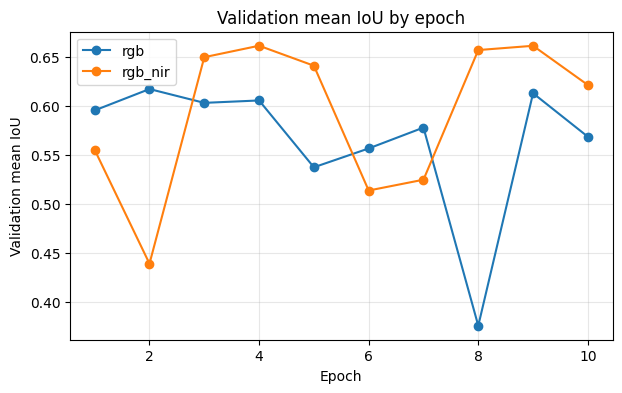

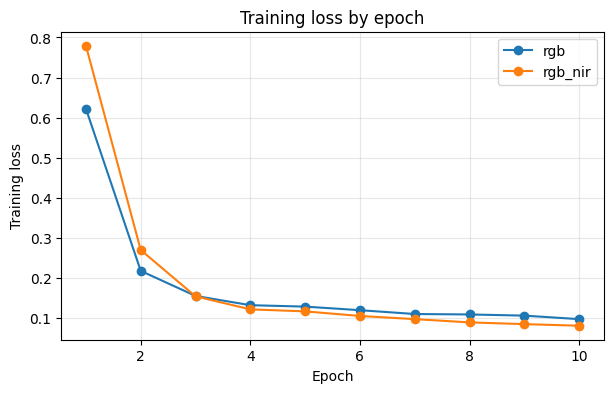

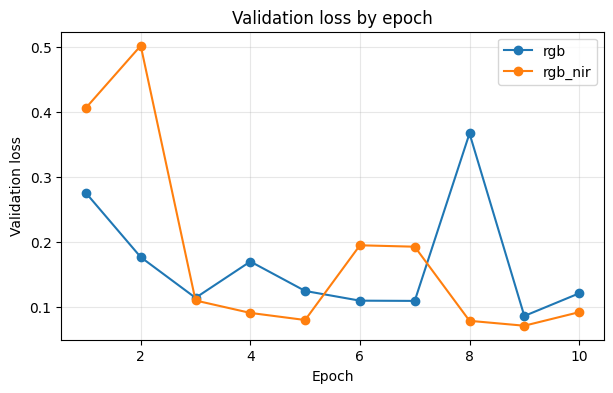

In [ ]:
def build_history_dataframe():
    # Checkpoints are the authoritative source, even if training is resumed later.
    rows = []
    for model_name in ("rgb", "rgb_nir"):
        for record in read_checkpoint(model_name, "latest")["history"]:
            iou = record["val_iou"]
            rows.append({
                "model": model_name, "epoch": record["epoch"],
                "train_loss": record["train_loss"], "val_loss": record["val_loss"],
                "soil_iou": iou[0], "crop_iou": iou[1],
                "grass_weed_iou": iou[2], "dicot_weed_iou": iou[3],
                "mean_iou": record["mean_iou"],
            })
    return pd.DataFrame(rows)

history_df = build_history_dataframe()
csv_path = RESULTS_DIR / "training_history.csv"
if csv_path.is_file():
    saved_history = pd.read_csv(csv_path)
    if len(saved_history) != len(history_df):
        print("Note: Drive CSV has a different number of rows than the latest checkpoints.")
        print("Plots below use the up-to-date checkpoint histories.")
else:
    print("History CSV not found; using the checkpoint histories.")

print("History rows:", len(history_df))
print(history_df.groupby("model")["epoch"].agg(["min", "max", "count"]))

for metric, ylabel in (("mean_iou", "Validation mean IoU"),
                        ("train_loss", "Training loss"),
                        ("val_loss", "Validation loss")):
    plt.figure(figsize=(7, 4))
    for model_name in ("rgb", "rgb_nir"):
        subset = history_df[history_df["model"] == model_name].sort_values("epoch")
        plt.plot(subset["epoch"], subset[metric], marker="o", label=model_name)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(f"{ylabel} by epoch")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

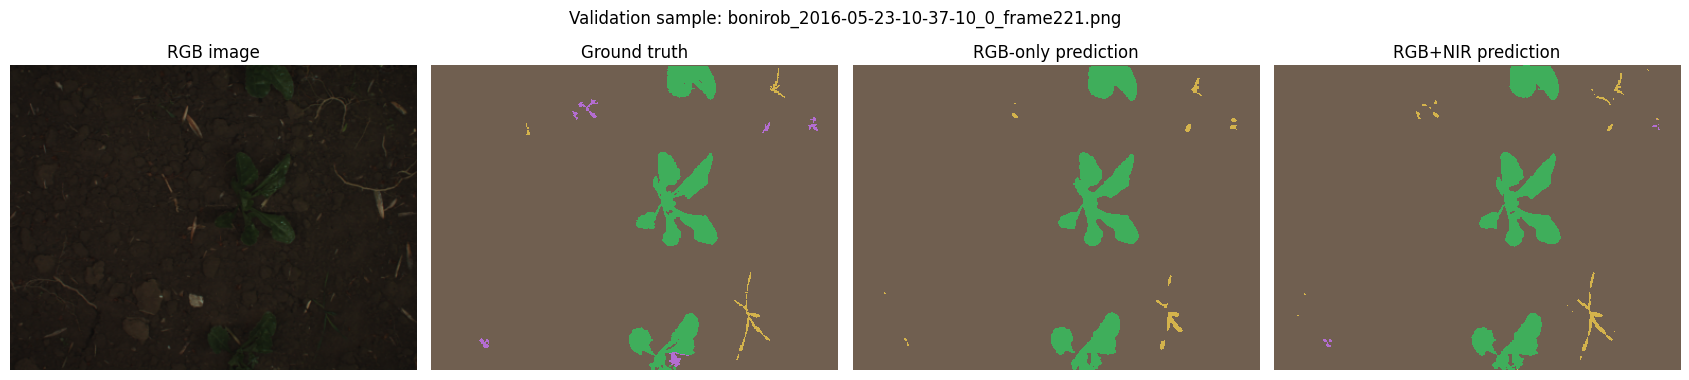

Legend: 0=Soil, 1=Crop, 2=Grass weed, 3=Dicot weed
Grey pixels are ignored (ground-truth class 255).


In [ ]:
SHOW_VALIDATION_EXAMPLE = True  # Safe: validation only; never evaluates the test set.

if SHOW_VALIDATION_EXAMPLE:
    # Choose a validation image containing dicot weed if possible.
    filename = next(
        (name for name in val_files if 3 in np.unique(prepare_sample(name)[2])),
        val_files[0]
    )
    rgb_image, rgb_nir_image, ground_truth = prepare_sample(filename)

    def predict_one(model, image):
        model.eval()
        tensor = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            return model(tensor).argmax(dim=1).squeeze(0).cpu().numpy()

    rgb_prediction = predict_one(best_models["rgb"], rgb_image)
    nir_prediction = predict_one(best_models["rgb_nir"], rgb_nir_image)
    # Ignore pixels are excluded from evaluation and hidden consistently in plots.
    valid = ground_truth != 255
    display_masks = [
        np.where(valid, ground_truth, np.nan),
        np.where(valid, rgb_prediction, np.nan),
        np.where(valid, nir_prediction, np.nan),
    ]

    from matplotlib.colors import ListedColormap, BoundaryNorm
    colors = ListedColormap(["#705f50", "#3fae5b", "#d4b34c", "#b36dd1"])
    colors.set_bad(color="#eeeeee")
    norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], colors.N)

    fig, axes = plt.subplots(1, 4, figsize=(17, 4))
    axes[0].imshow(rgb_image)
    axes[0].set_title("RGB image")
    for ax, mask, title in zip(
        axes[1:], display_masks,
        ("Ground truth", "RGB-only prediction", "RGB+NIR prediction")
    ):
        ax.imshow(mask, cmap=colors, norm=norm, interpolation="nearest")
        ax.set_title(title)
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"Validation sample: {filename}")
    plt.tight_layout()
    plt.show()
    print("Legend:", ", ".join(f"{i}={name}" for i, name in enumerate(CLASS_NAMES)))
    print("Grey pixels are ignored (ground-truth class 255).")
else:
    print("Validation visualisation skipped.")


In [ ]:
def save_training_checkpoint(model, optimizer, model_name, epoch,
                             train_loss, val_loss, val_iou, best_miou, history, save_dir=None):
    current_miou = float(np.nanmean(val_iou))
    is_best = current_miou > best_miou
    updated_best = max(best_miou, current_miou)
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_iou": val_iou.tolist(),
        "mean_iou": current_miou,
        "best_val_miou": updated_best,
        "history": history,
        "seed": SEED,
    }

    save_dir = Path(save_dir) if save_dir is not None else CHECKPOINT_DIR
    save_dir.mkdir(parents=True, exist_ok=True)
    latest_tmp = save_dir / f"{model_name}_latest.tmp"
    torch.save(checkpoint, latest_tmp)
    latest_tmp.replace(save_dir / f"{model_name}_latest.pt")
    if is_best:
        best_tmp = save_dir / f"{model_name}_best.tmp"
        torch.save(checkpoint, best_tmp)
        best_tmp.replace(save_dir / f"{model_name}_best.pt")

    print(f"{model_name} | epoch {epoch} | val mIoU {current_miou:.4f} | new best: {is_best}")
    return updated_best


def run_training(model, train_loader, val_loader, optimizer, model_name,
                 start_epoch, end_epoch, history, best_miou, save_dir=None):
    for epoch in range(start_epoch, end_epoch + 1):
        # Both experiments use the same shuffle seed for each *new* epoch.
        train_loader.generator.manual_seed(SEED + epoch)
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
        val_loss = validate_one_epoch(model, val_loader, criterion, DEVICE)
        val_iou = evaluate_iou(model, val_loader, DEVICE)
        record = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "val_iou": val_iou.tolist(),
            "mean_iou": float(np.nanmean(val_iou)),
        }
        history.append(record)
        best_miou = save_training_checkpoint(
            model, optimizer, model_name, epoch, train_loss, val_loss,
            val_iou, best_miou, history, save_dir=save_dir
        )
        print(" | ".join(f"{name}: {score:.4f}" for name, score in zip(CLASS_NAMES, val_iou)))
    return history, best_miou

print("Optional training/resume functions ready; no training started.")

Optional training/resume functions ready; no training started.


In [ ]:
CONTINUE_TRAINING = False
TARGET_EPOCH = 10  # Already completed; increase only if additional training is approved.

if CONTINUE_TRAINING:
    if DEVICE.type != "cuda":
        raise RuntimeError("Enable a GPU runtime before resuming training.")
    for model_name, channels, train_loader, val_loader in (
        ("rgb", 3, train_rgb_loader, val_rgb_loader),
        ("rgb_nir", 4, train_rgb_nir_loader, val_rgb_nir_loader),
    ):
        checkpoint = read_checkpoint(model_name, "latest", map_location=DEVICE)
        completed_epoch = int(checkpoint["epoch"])
        if completed_epoch >= TARGET_EPOCH:
            print(f"{model_name}: already at epoch {completed_epoch}; skipping")
            continue

        model = UNet(in_channels=channels, num_classes=4).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = list(checkpoint["history"])
        best_miou = float(checkpoint["best_val_miou"])
        print(f"Resuming {model_name} from epoch {completed_epoch + 1} to {TARGET_EPOCH}")
        run_training(model, train_loader, val_loader, optimizer, model_name,
                     completed_epoch + 1, TARGET_EPOCH, history, best_miou)
        del model, optimizer
        torch.cuda.empty_cache()
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    build_history_dataframe().to_csv(RESULTS_DIR / "training_history.csv", index=False)
    print("Training complete and history CSV updated. Rerun Section 7 to load new best models.")
else:
    print("Training skipped: using the saved 10-epoch checkpoints.")

Training skipped: using the saved 10-epoch checkpoints.


In [ ]:
RETRAIN_FROM_SCRATCH = False  # Leave False for normal lecturer/teammate review.
REPRODUCTION_EPOCHS = 10
REPRODUCTION_LR = 0.001
REPRODUCTION_DIR = PROJECT_DIR / "reproduction_checkpoints"

if RETRAIN_FROM_SCRATCH:
    if DEVICE.type != "cuda":
        raise RuntimeError("Enable a GPU runtime before retraining from scratch.")
    if any((REPRODUCTION_DIR / f"{name}_latest.pt").exists() for name in ("rgb", "rgb_nir")):
        raise FileExistsError(
            f"Reproduction checkpoints already exist in {REPRODUCTION_DIR}. "
            "Do not overwrite them: resume explicitly or use a new folder."
        )

    for model_name, channels, train_loader, val_loader in (
        ("rgb", 3, train_rgb_loader, val_rgb_loader),
        ("rgb_nir", 4, train_rgb_nir_loader, val_rgb_nir_loader),
    ):
        set_seed(SEED)
        model = UNet(in_channels=channels, num_classes=4).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=REPRODUCTION_LR)
        print(f"Reproducing {model_name}: {REPRODUCTION_EPOCHS} epochs, Adam lr={REPRODUCTION_LR}")
        history, best_miou = run_training(
            model=model, train_loader=train_loader, val_loader=val_loader,
            optimizer=optimizer, model_name=model_name,
            start_epoch=1, end_epoch=REPRODUCTION_EPOCHS,
            history=[], best_miou=float("-inf"), save_dir=REPRODUCTION_DIR
        )
        print(f"Reproduction finished for {model_name}; best validation mIoU: {best_miou:.4f}")
        del model, optimizer
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
else:
    print("Full retraining skipped. Original checkpoints remain unchanged.")


Full retraining skipped. Original checkpoints remain unchanged.


In [ ]:
def convert_original_mask(original_mask):
    converted = np.full(original_mask.shape, 255, dtype=np.uint8)
    converted[np.isin(original_mask, [0, 1, 97])] = 0
    converted[np.isin(original_mask, [10000, 10001, 10002])] = 1
    converted[np.isin(original_mask, range(20100, 20106))] = 2
    converted[np.isin(original_mask, range(20000, 20012))] = 3
    return converted

print("Original annotation mapping documented; no files modified.")

Original annotation mapping documented; no files modified.


In [ ]:
REGENERATE_MASKS = False

if REGENERATE_MASKS:
    original_mask_dir = dataset_dir / "annotations/dlp/iMapCleaned"
    regenerated_dir = Path("/content/reproduction_masks")
    if not original_mask_dir.is_dir():
        raise FileNotFoundError(f"Original annotations not found: {original_mask_dir}")
    regenerated_dir.mkdir(parents=True, exist_ok=True)
    converted_count = 0
    for filename in all_filenames:
        original = cv2.imread(str(original_mask_dir / filename), cv2.IMREAD_UNCHANGED)
        if original is None:
            raise FileNotFoundError(filename)
        converted = convert_original_mask(original)
        if not cv2.imwrite(str(regenerated_dir / filename), converted):
            raise IOError(f"Could not save {filename}")
        converted_count += 1
    assert converted_count == 921
    print("Regenerated masks:", converted_count, "in", regenerated_dir)
    # Check a representative file against the mask used in the experiment.
    sample_name = train_files[0]
    original_saved = cv2.imread(str(output_dir / sample_name), cv2.IMREAD_UNCHANGED)
    regenerated = cv2.imread(str(regenerated_dir / sample_name), cv2.IMREAD_UNCHANGED)
    print("Representative mask matches original conversion:",
          np.array_equal(original_saved, regenerated))
else:
    print("Mask regeneration skipped: existing four-class masks are preserved.")


Mask regeneration skipped: existing four-class masks are preserved.


# **Segmentation Performance Measurement**

In [ ]:
def compute_confusion_matrix(model, loader, device, num_classes=4):
    model.eval()
    conf_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            predicted_masks = model(images).argmax(dim=1)
            valid_pixels = masks != 255
            true_labels = masks[valid_pixels]
            pred_labels = predicted_masks[valid_pixels]
            combined = true_labels * num_classes + pred_labels
            counts = torch.bincount(combined, minlength = num_classes**2)
            conf_matrix += counts.reshape(num_classes, num_classes).cpu().numpy()

    return conf_matrix

conf_matrix_nir = compute_confusion_matrix(best_models["rgb_nir"], val_rgb_nir_loader, DEVICE)
print(conf_matrix_nir)

[[8525895   15523   63382    1993]
 [   9260  584213    1675      30]
 [   7225    3458  114974    1619]
 [   3149    1934    2104    1432]]


In [ ]:
def metrics_from_confusion(cm):
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    iou = tp/(tp+fp+fn)
    precision = tp/(tp+fp)
    recall = tp/(tp+fn)
    f1 = 2*precision*recall/(precision+recall)
    df = pd.DataFrame({
        "Class": ["Soil", "Crop (Sugar Beet)", "Grass weed (NLW)", "Dicot weed (BLW)"],
        "IoU": iou,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })
    print(df)
    miou_all = np.nanmean(iou)
    miou_plants = np.nanmean(iou[1:])
    print(f"mIoU (all 4): {miou_all:.4f} | mIoU (plants only): {miou_plants:.4f}")
    return iou, precision, recall, f1, miou_all, miou_plants, df

conf_matrix_nir = compute_confusion_matrix(best_models["rgb_nir"], val_rgb_nir_loader, DEVICE)
conf_matrix_rgb = compute_confusion_matrix(best_models["rgb"], val_rgb_loader, DEVICE)

print("RGB + NIR")
nir_results = metrics_from_confusion(conf_matrix_nir)
print("RGB")
rgb_results = metrics_from_confusion(conf_matrix_rgb)

#For comparison
print(evaluate_iou(best_models["rgb_nir"], val_rgb_nir_loader, DEVICE))
print(evaluate_iou(best_models["rgb"], val_rgb_loader, DEVICE))


RGB + NIR
               Class       IoU  Precision    Recall        F1
0               Soil  0.988346   0.997702  0.990601  0.994139
1  Crop (Sugar Beet)  0.948255   0.965437  0.981577  0.973440
2   Grass weed (NLW)  0.591317   0.631257  0.903344  0.743180
3   Dicot weed (BLW)  0.116793   0.282223  0.166145  0.209158
mIoU (all 4): 0.6612 | mIoU (plants only): 0.5521
RGB
               Class       IoU  Precision    Recall        F1
0               Soil  0.987429   0.995151  0.992203  0.993675
1  Crop (Sugar Beet)  0.909386   0.948176  0.956951  0.952543
2   Grass weed (NLW)  0.571129   0.660312  0.808746  0.727030
3   Dicot weed (BLW)  0.000000        NaN  0.000000       NaN
mIoU (all 4): 0.6170 | mIoU (plants only): 0.4935


/tmp/ipykernel_1251/2296337134.py:6: RuntimeWarning: invalid value encountered in divide
  precision = tp/(tp+fp)


[0.98834604 0.94825457 0.5913175  0.11679308]
[0.98742912 0.90938644 0.57112895 0.        ]


In [ ]:
test_cm_nir = compute_confusion_matrix(best_models["rgb_nir"], test_rgb_nir_loader, DEVICE)
test_cm_rgb = compute_confusion_matrix(best_models["rgb"], test_rgb_loader, DEVICE)

print("RGB + NIR")
test_nir_results = metrics_from_confusion(test_cm_nir)
print("RGB")
test_rgb_results = metrics_from_confusion(test_cm_rgb)

metrics_dir = RESULTS_DIR/"metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
np.save(metrics_dir/"test_cm_rgb_nir.npy", test_cm_nir)
np.save(metrics_dir/"test_cm_rgb.npy", test_cm_rgb)

_,_,_,_, nir_miou_all, nir_miou_plants, nir_df = test_nir_results
_,_,_,_, rgb_miou_all, rgb_miou_plants, rgb_df = test_rgb_results

summary = pd.DataFrame({
    "Model": ["RGB", "RGB+NIR"],
    "mIoU (all 4)": [rgb_miou_all, nir_miou_all],
    "mIoU (plants only)": [rgb_miou_plants, nir_miou_plants],
})
summary.to_csv(metrics_dir / "test_miou_summary.csv", index=False)

nir_df.to_csv(metrics_dir/"test_metrics_rgb_nir.csv", index=False)
rgb_df.to_csv(metrics_dir/"test_metrics_rgb.csv", index=False)

print(sorted(p.name for p in metrics_dir.iterdir()))

RGB + NIR
               Class       IoU  Precision    Recall        F1
0               Soil  0.989313   0.997646  0.991628  0.994628
1  Crop (Sugar Beet)  0.918100   0.950661  0.964035  0.957302
2   Grass weed (NLW)  0.529594   0.592531  0.832942  0.692463
3   Dicot weed (BLW)  0.088767   0.167556  0.158798  0.163059
mIoU (all 4): 0.6314 | mIoU (plants only): 0.5122
RGB
               Class       IoU  Precision    Recall        F1
0               Soil  0.987267   0.995267  0.991923  0.993593
1  Crop (Sugar Beet)  0.879345   0.933077  0.938537  0.935799
2   Grass weed (NLW)  0.483887   0.560212  0.780300  0.652188
3   Dicot weed (BLW)  0.000000        NaN  0.000000       NaN
mIoU (all 4): 0.5876 | mIoU (plants only): 0.4544


/tmp/ipykernel_1251/2296337134.py:6: RuntimeWarning: invalid value encountered in divide
  precision = tp/(tp+fp)


['per_image_scores_rgb_nir.csv', 'test_binary_any_weed_including_generic.csv', 'test_binary_any_weed_per_image_counts.csv', 'test_binary_weed_evaluation.csv', 'test_cm_rgb.npy', 'test_cm_rgb_nir.npy', 'test_metrics_rgb.csv', 'test_metrics_rgb_nir.csv', 'test_miou_summary.csv', 'test_weed_level_detection.csv']


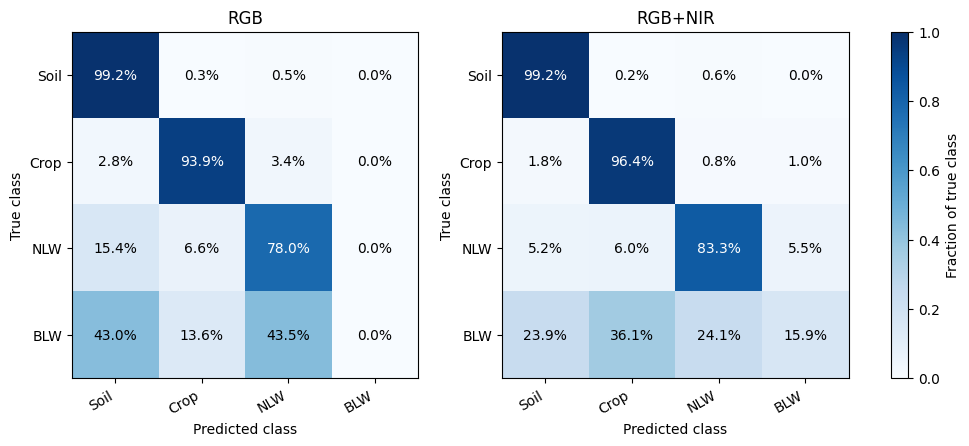

In [ ]:
class_labels = ["Soil", "Crop", "NLW", "BLW"]
panels = [("RGB", test_cm_rgb), ("RGB+NIR", test_cm_nir)]

fig, axes = plt.subplots(1, 2, figsize = (11, 4.5))

for ax, (title, cm) in zip(axes, panels):
    cm_norm = cm/cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels(class_labels, rotation=30, ha="right")
    ax.set_xlabel("Predicted class")
    ax.set_yticklabels(class_labels)
    ax.set_ylabel("True class")
    ax.set_title(title)

    for i in range(4):
        for j in range(4):
            value = cm_norm[i,j]
            ax.text(j, i, f"{value*100:.1f}%", ha="center", va="center", color="white" if value > 0.5 else "black")

fig.colorbar(im, ax=axes, fraction=0.025, label="Fraction of true class")
figures_dir = RESULTS_DIR/"figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figures_dir/"fig3_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
model = best_models["rgb_nir"]
model.eval()
rows = []

with torch.no_grad():
    for idx, filename in enumerate(test_files):
        image, mask = test_rgb_nir_dataset[idx]
        image, mask = image.unsqueeze(0).to(DEVICE), mask.to(DEVICE)

        pred = model(image).argmax(dim=1).squeeze(0)

        valid = mask != 255
        combined = mask[valid] * 4 + pred[valid]
        cm_img = torch.bincount(combined, minlength=16).reshape(4, 4).cpu().numpy()

        tp = np.diag(cm_img)
        fn = cm_img.sum(axis=1) - tp
        fp = cm_img.sum(axis=0) - tp
        with np.errstate(invalid="ignore", divide="ignore"):
            iou = tp/(tp+fp+fn)

        rows.append({
            "filename": filename,
            "plant_miou": np.nanmean(iou[1:]),
            "dicot_pixels": int((mask == 3).sum()),
            "crop_iou": iou[1], "grass_iou": iou[2], "dicot_iou": iou[3],
            "soil_as_grass": int(cm_img[0,2]),
        })

per_image = pd.DataFrame(rows).sort_values("plant_miou", ascending=False).reset_index(drop=True)
per_image.to_csv(RESULTS_DIR/"metrics"/"per_image_scores_rgb_nir.csv", index=False)
print(per_image.head(), per_image.tail())

best = per_image.iloc[0]
typical = per_image.iloc[len(per_image)//2]
worst = per_image.iloc[-1]
print(best, typical, worst, sep="\n\n")

per_image["recording"] = per_image["filename"].str.rsplit("_frame", n=1).str[0]
print(per_image.groupby("recording")["plant_miou"].agg(["mean", "std", "count"]))

                                     filename  plant_miou  dicot_pixels  \
0    bonirob_2016-05-23-10-52-28_3_frame3.png    0.777618             0   
1   bonirob_2016-05-23-10-52-28_3_frame64.png    0.772328             0   
2   bonirob_2016-05-23-10-52-28_3_frame39.png    0.738642             0   
3  bonirob_2016-05-23-10-37-10_0_frame305.png    0.627129            35   
4  bonirob_2016-05-23-10-37-10_0_frame272.png    0.616206           346   

   crop_iou  grass_iou  dicot_iou  soil_as_grass  
0  0.972687   0.582550        NaN            611  
1  0.962956   0.581699        NaN             52  
2  0.959653   0.517630        NaN            314  
3  0.964116   0.695049   0.222222            751  
4  0.950232   0.559449   0.338936            214                                          filename  plant_miou  dicot_pixels  \
117   bonirob_2016-05-23-10-52-28_3_frame93.png    0.288218             0   
118  bonirob_2016-05-23-10-37-10_0_frame283.png    0.271579          1973   
119   boniro

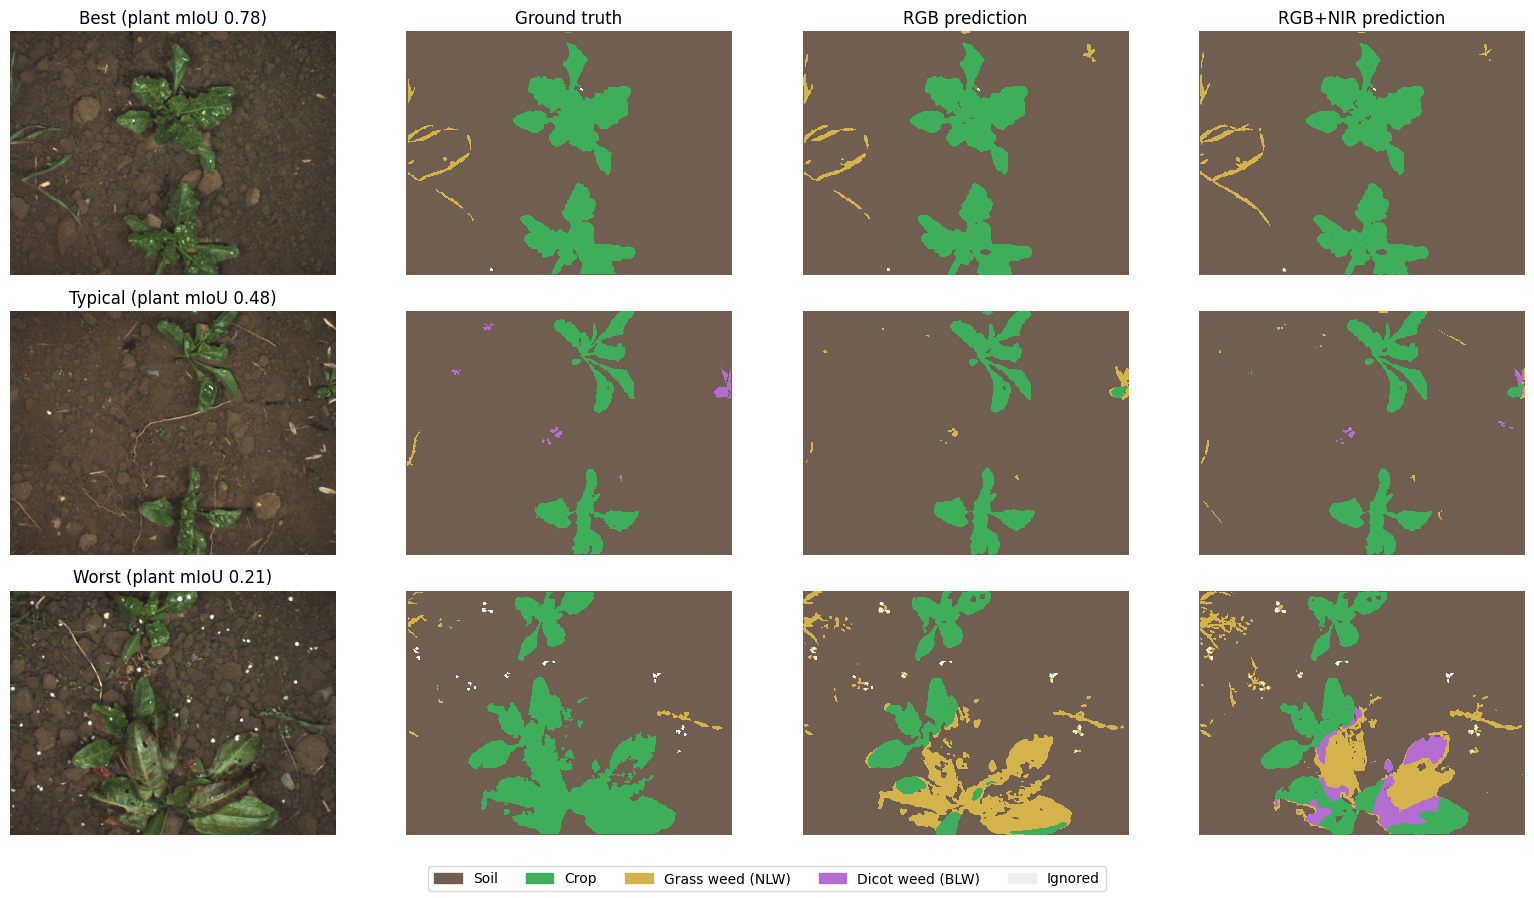

In [ ]:
from matplotlib.patches import Patch

picks = [("Best", best), ("Typical", typical), ("Worst", worst)]
fig, axes = plt.subplots(3, 4, figsize = (16,9))

for row, (label, info) in enumerate(picks):
    rgb, rgb_nir, gt = prepare_sample(info["filename"])
    pred_rgb = predict_one(best_models["rgb"], rgb)
    pred_nir = predict_one(best_models["rgb_nir"], rgb_nir)
    valid = gt != 255
    panels = [rgb,
              np.where(valid, gt, np.nan),
              np.where(valid, pred_rgb, np.nan),
              np.where(valid, pred_nir, np.nan)]
    for col, img in enumerate(panels):
        ax = axes[row, col]
        if col == 0:
            ax.imshow(np.clip(img * 2.5, 0, 1))
        else:
            ax.imshow(img, cmap=colors, norm=norm, interpolation="nearest")
        ax.axis("off")
    axes[row, 0].set_title(f"{label} (plant mIoU {info['plant_miou']:.2f})")

axes[0,1].set_title("Ground truth")
axes[0,2].set_title("RGB prediction")
axes[0,3].set_title("RGB+NIR prediction")

handles = [
    Patch(color = "#705f50", label="Soil"),
    Patch(color = "#3fae5b", label="Crop"),
    Patch(color = "#d4b34c", label="Grass weed (NLW)"),
    Patch(color = "#b36dd1", label="Dicot weed (BLW)"),
    Patch(color = "#eeeeee", label="Ignored"),
    ]

fig.legend(handles=handles, loc="lower center", ncol=5)
plt.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(figures_dir/"fig5_examples.png", dpi=300, bbox_inches="tight")
plt.show()

filename         bonirob_2016-05-23-10-52-28_3_frame93.png
plant_miou                                        0.288218
dicot_pixels                                             0
crop_iou                                          0.415863
grass_iou                                         0.448789
dicot_iou                                              0.0
soil_as_grass                                         8222
recording                    bonirob_2016-05-23-10-52-28_3
Name: 117, dtype: object


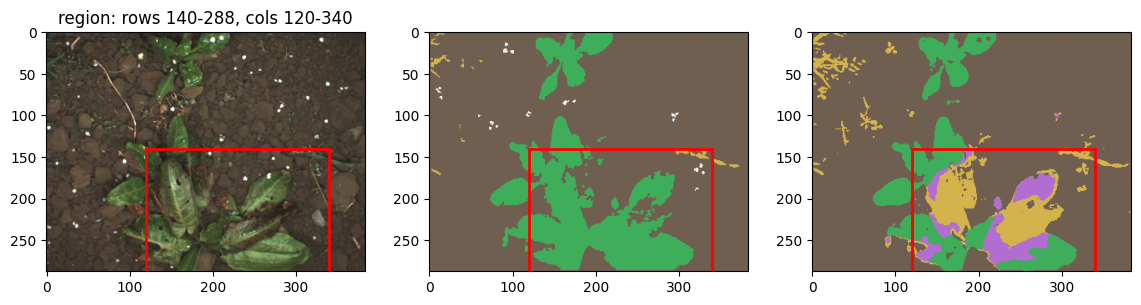

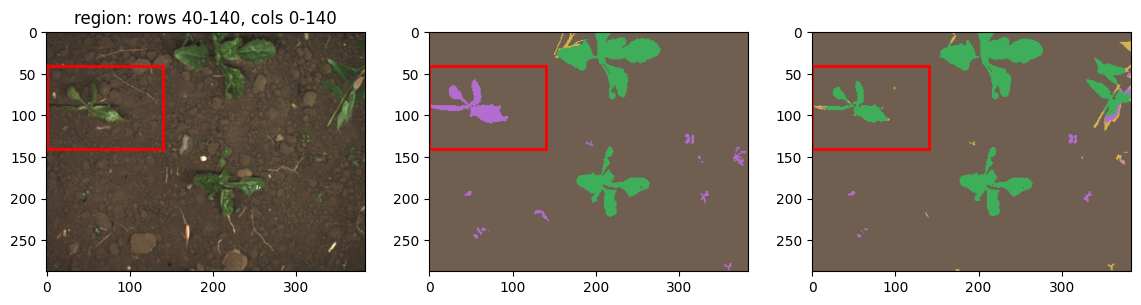

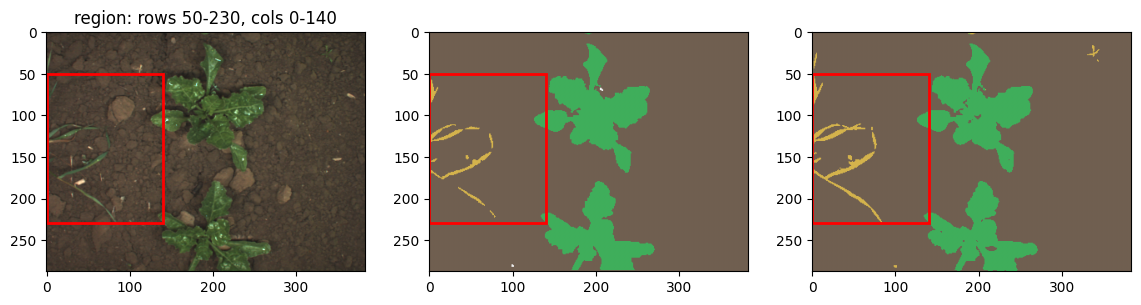

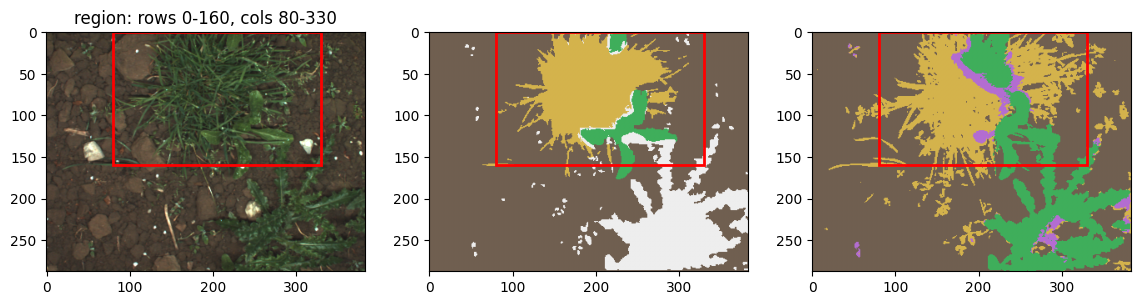

In [ ]:
from matplotlib.patches import Rectangle

top_soil_grass = per_image.sort_values("soil_as_grass", ascending=False).iloc[0]
print(top_soil_grass)
case_d_file = top_soil_grass["filename"]

def preview(fname, region):
    rgb, rgb_nir, gt = prepare_sample(fname)
    pr = predict_one(best_models["rgb_nir"], rgb_nir)
    gt_show = np.where(gt != 255, gt, np.nan)
    y0, y1, x0, x1 = region

    fig, axes = plt.subplots(1, 3, figsize = (14,4))
    axes[0].imshow(np.clip(rgb*2.5, 0, 1))
    axes[1].imshow(gt_show, cmap=colors, norm=norm)
    axes[2].imshow(pr, cmap=colors, norm=norm)
    for ax in axes:
        ax.add_patch(Rectangle((x0,y0), x1-x0, y1-y0, fill=False, edgecolor="red", linewidth = 2))
    axes[0].set_title(f"region: rows {y0}-{y1}, cols {x0}-{x1}")
    plt.show()

preview("bonirob_2016-05-23-10-52-28_3_frame82.png", (140, 288, 120, 340))
preview("bonirob_2016-05-23-10-37-10_0_frame283.png", (40, 140, 0, 140))
preview("bonirob_2016-05-23-10-52-28_3_frame3.png", (50, 230, 0, 140))
preview(case_d_file, (0, 160, 80, 330))


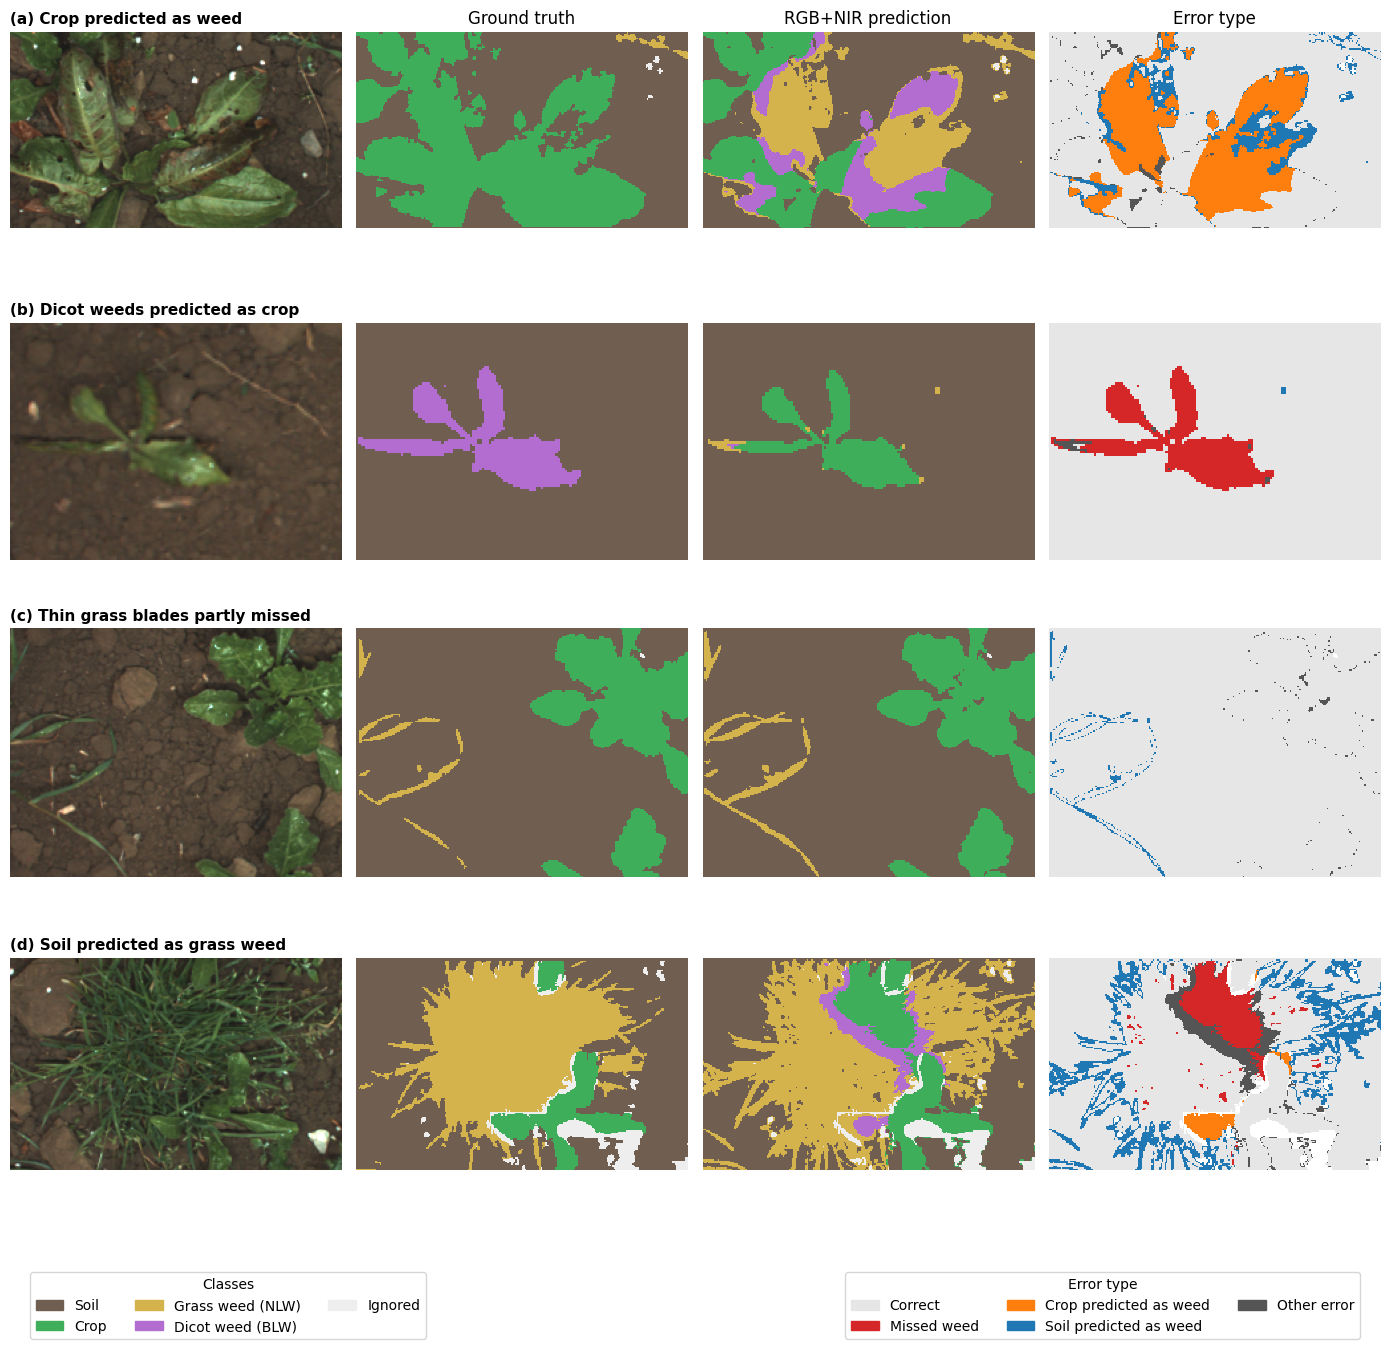

In [ ]:
def make_error_map(gt, pr):
    weed_true = np.isin(gt, [2,3])
    weed_pred = np.isin(pr, [2,3])

    err = np.full(gt.shape, 4.0)
    err[weed_true & ~weed_pred] = 1
    err[(gt == 1) & weed_pred] = 2
    err[(gt == 0) & weed_pred] = 3
    err[gt == pr] = 0
    err[gt == 255] = np.nan
    return err

err_colors = ListedColormap(["#e6e6e6",
                             "#d62728",
                             "#ff7f0e",
                             "#1f77b4",
                             "#555555"])
err_colors.set_bad("white")
err_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], err_colors.N)

cases = [
    {"name": "(a) Crop predicted as weed",
     "file": "bonirob_2016-05-23-10-52-28_3_frame82.png",
     "region": (140, 288, 100, 350)},
    {"name": "(b) Dicot weeds predicted as crop",
     "file": "bonirob_2016-05-23-10-37-10_0_frame283.png",
     "region": (40, 140, 0, 140)},
    {"name": "(c) Thin grass blades partly missed",
     "file": "bonirob_2016-05-23-10-52-28_3_frame3.png",
     "region": (50, 230, 0, 240)},
    {"name": "(d) Soil predicted as grass weed",
     "file": case_d_file,
     "region": (0, 160, 80, 330)},
]

fig, axes = plt.subplots(len(cases), 4, figsize = (14, 3.5*len(cases)))

for row, case in enumerate(cases):
    rgb, rgb_nir, gt = prepare_sample(case["file"])
    pr = predict_one(best_models["rgb_nir"], rgb_nir)
    err = make_error_map(gt, pr)
    y0, y1, x0, x1 = case["region"]
    gt_show = np.where(gt != 255, gt, np.nan)
    pr_show = np.where(gt != 255, pr, np.nan)
    s = (slice(y0, y1), slice(x0, x1))

    axes[row, 0].imshow(np.clip(rgb[s] * 2.5, 0, 1))
    axes[row, 1].imshow(gt_show[s], cmap=colors, norm=norm, interpolation="nearest")
    axes[row, 2].imshow(pr_show[s], cmap=colors, norm=norm, interpolation="nearest")
    axes[row, 3].imshow(err[s], cmap=err_colors, norm=err_norm, interpolation="nearest")

    for ax in axes[row]:
        ax.axis("off")
    axes[row, 0].set_title(case["name"], loc="left", fontsize=11, fontweight="bold")

for col, title in enumerate(["Ground truth", "RGB+NIR prediction", "Error type"], start=1):
    axes[0, col].set_title(title)

class_handles = [
    Patch(color = "#705f50", label="Soil"),
    Patch(color = "#3fae5b", label="Crop"),
    Patch(color = "#d4b34c", label="Grass weed (NLW)"),
    Patch(color = "#b36dd1", label="Dicot weed (BLW)"),
    Patch(color = "#eeeeee", label="Ignored"),
    ]

err_handles = [
    Patch(color = "#e6e6e6", label="Correct"),
    Patch(color = "#d62728", label="Missed weed"),
    Patch(color = "#ff7f0e", label="Crop predicted as weed"),
    Patch(color = "#1f77b4", label="Soil predicted as weed"),
    Patch(color = "#555555", label="Other error"),
    ]

fig.legend(handles=class_handles, loc="lower left", ncol=3, bbox_to_anchor=(0.02, 0.0), title="Classes")
fig.legend(handles=err_handles, loc="lower right", ncol=3, bbox_to_anchor=(0.98, 0.0), title="Error type")
plt.tight_layout(rect=[0, 0.07, 1, 1])

fig.savefig(figures_dir/"fig6_failure_cases.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
def find_weed_patches(pred_mask, class_id, class_name, min_area=20):
    binary = (pred_mask == class_id).astype(np.uint8)
    num, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)

    patches = []
    for i in range(1, num):
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue
        cx, cy = centroids[i]
        patches.append({
            "type": class_name,
            "x_centre": round(cx, 1), "y_centre": round(cy, 1),
            "x": x, "y": y, "width": w, "height": h,
            "area_px": area,
        })
    return patches

fname = typical["filename"]
rgb, rgb_nir, gt = prepare_sample(fname)
pr = predict_one(best_models["rgb_nir"], rgb_nir)

patches = find_weed_patches(pr, 2, "Grass weed (NLW)") + find_weed_patches(pr, 3, "Dicot weed (BLW)")
patch_table = pd.DataFrame(patches)
print(len(patch_table), "weed patches found")
print(patch_table)

9 weed patches found
               type  x_centre  y_centre    x    y  width  height  area_px
0  Grass weed (NLW)     217.1       1.6  212    0     11       4       34
1  Grass weed (NLW)     303.1      34.7  292   29     22      12       34
2  Grass weed (NLW)     381.5      98.9  378   89      6      16       32
3  Grass weed (NLW)       9.2     161.1    7  153      5      17       51
4  Grass weed (NLW)       4.0     176.4    2  172      5       9       22
5  Grass weed (NLW)     251.9     196.8  248  194      7       8       27
6  Dicot weed (BLW)     377.4      77.9  371   68     12      20      122
7  Dicot weed (BLW)     356.2     133.1  352  130      9       8       26
8  Dicot weed (BLW)     177.4     143.5  170  138     14      12       70


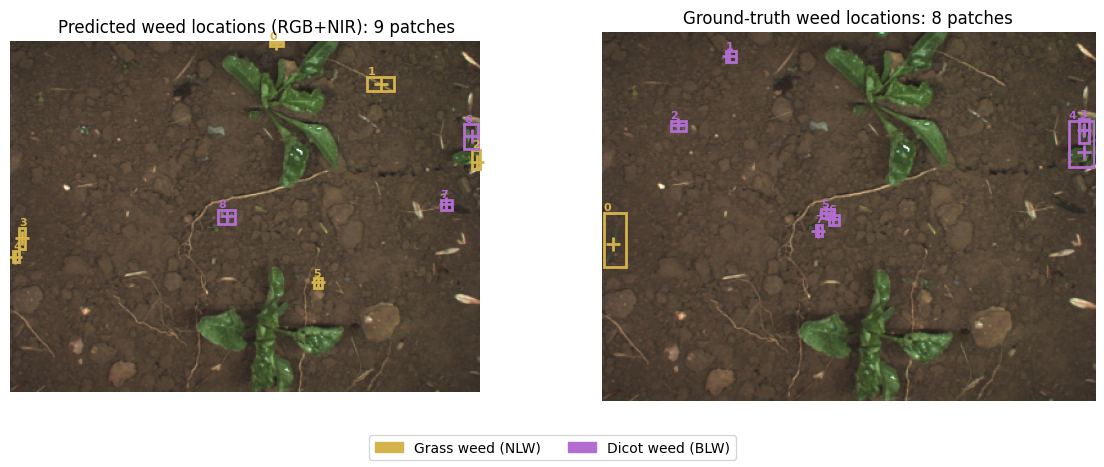

In [ ]:
gt_clean = np.where(gt == 255, 0, gt)
gt_patches = pd.DataFrame(find_weed_patches(gt_clean, 2, "Grass weed (NLW)") +
                          find_weed_patches(gt_clean, 3, "Dicot weed (BLW)"))

type_colors = {"Grass weed (NLW)": "#d4b34c", "Dicot weed (BLW)": "#b36dd1"}

fig, axes = plt.subplots(1, 2, figsize = (14, 5))
for ax, table, title in [(axes[0], patch_table, "Predicted weed locations (RGB+NIR)"),
                         (axes[1], gt_patches, "Ground-truth weed locations")]:

    ax.imshow(np.clip(rgb * 2.5, 0, 1))
    for i, p in table.iterrows():
        c = type_colors[p["type"]]
        ax.add_patch(Rectangle((p["x"], p["y"]), p["width"], p["height"], fill=False, edgecolor=c, linewidth=2))
        ax.plot(p["x_centre"], p["y_centre"], marker="+", color=c, markersize=10, mew=2)
        ax.text(p["x"], p["y"]-2, str(i), color=c, fontsize=8, fontweight="bold")
    ax.set_title(f"{title}: {len(table)} patches")
    ax.axis("off")

map_handles = [Patch(color = type_colors[t], label=t) for t in type_colors]
fig.legend(handles=map_handles, loc="lower center", ncol=2)
fig.savefig(figures_dir/"fig7_weed_detection_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
def weed_level_counts(gt, pr, min_area=20):
    gt_weed = np.isin(gt, [2, 3]).astype(np.uint8)
    pr_weed = np.isin(pr, [2, 3]).astype(np.uint8)

    n_gt, labels_gt, stats_gt, _ = cv2.connectedComponentsWithStats(gt_weed, connectivity=8)
    n_pr, labels_pr, stats_pr, _ = cv2.connectedComponentsWithStats(pr_weed, connectivity=8)

    gt_keep_ids = [k for k in range(1, n_gt) if stats_gt[k, 4] >= min_area]
    pr_keep_ids = [k for k in range(1, n_pr) if stats_pr[k, 4] >= min_area]
    gt_kept = np.isin(labels_gt, gt_keep_ids)
    pr_kept = np.isin(labels_pr, pr_keep_ids)

    gt_total = gt_detected = 0
    for k in range(1, n_gt):
        if stats_gt[k, 4] < min_area:
            continue
        gt_total += 1
        if pr_kept[labels_gt == k].any():
            gt_detected += 1

    pr_total = pr_correct = 0
    for k in range(1, n_pr):
        if stats_pr[k, 4] < min_area:
            continue
        pr_total += 1
        if gt_kept[labels_pr == k].any():
            pr_correct += 1

    return gt_total, gt_detected, pr_total, pr_correct

rgb, rgb_nir, gt = prepare_sample(typical["filename"])
pr = predict_one(best_models["rgb_nir"], rgb_nir)
print(weed_level_counts(gt, pr))

(8, 5, 8, 4)


In [ ]:
totals = {"RGB": np.zeros(4, dtype=int), "RGB+NIR": np.zeros(4, dtype=int)}

for fname in test_files:
    rgb, rgb_nir, gt = prepare_sample(fname)
    pr_rgb = predict_one(best_models["rgb"], rgb)
    pr_nir = predict_one(best_models["rgb_nir"], rgb_nir)
    totals["RGB"] += np.array(weed_level_counts(gt, pr_rgb))
    totals["RGB+NIR"] += np.array(weed_level_counts(gt, pr_nir))

rows = []
for model_name, (gt_total, gt_det, pr_total, pr_ok) in totals.items():
    rows.append({
        "Model": model_name,
        "Real weeds": gt_total,
        "Detected": gt_det,
        "Weed-level recall": gt_det/gt_total,
        "Predicted weeds": pr_total,
        "Correct": pr_ok,
        "Weed-level precision": pr_ok/pr_total,

    })

weed_table = pd.DataFrame(rows)
print(weed_table)
weed_table.to_csv(RESULTS_DIR/"metrics"/"test_weed_level_detection.csv", index=False)


     Model  Real weeds  Detected  Weed-level recall  Predicted weeds  Correct  \
0      RGB         693       507           0.731602             1348      566   
1  RGB+NIR         693       573           0.826840             1232      429   

   Weed-level precision  
0              0.419881  
1              0.348214  


In [ ]:
#Binary Weed Detection

In [ ]:
# Binary weed evaluation using the existing trained models

original_mask_dir = dataset_dir / "annotations/dlp/iMapCleaned"
assert original_mask_dir.is_dir(), "Original annotation folder not found"

binary_results = []

for model_name, model_key in [("RGB", "rgb"), ("RGB+NIR", "rgb_nir")]:

    model = best_models[model_key]
    model.eval()

    TP = FP = FN = TN = 0
    generic_total = generic_detected = 0
    crop_total = crop_detected_as_weed = 0

    with torch.inference_mode():

        for filename in test_files:

            # Load preprocessed images
            rgb, rgb_nir, converted_mask = prepare_sample(filename)

            # Load ORIGINAL annotation labels
            original = cv2.imread(
                str(original_mask_dir / filename),
                cv2.IMREAD_UNCHANGED
            )

            if original is None:
                raise FileNotFoundError(filename)

            original = cv2.resize(
                original, (384, 288),
                interpolation=cv2.INTER_NEAREST
            )

            # Identify original ground-truth categories
            soil = np.isin(original, [0, 1, 97])
            crop = np.isin(original, [10000, 10001, 10002])
            grass = (original >= 20100) & (original <= 20105)
            dicot = (original >= 20000) & (original <= 20011)
            generic = original == 2

            # Include generic weeds in the binary ground truth
            actual_weed = grass | dicot | generic
            valid = soil | crop | grass | dicot | generic

            # Choose correct input for each trained model
            image = rgb if model_key == "rgb" else rgb_nir

            tensor = torch.from_numpy(image).permute(
                2, 0, 1
            ).unsqueeze(0).to(DEVICE)

            # Existing four-class prediction
            prediction = model(tensor).argmax(
                dim=1
            ).squeeze(0).cpu().numpy()

            # Grass OR dicot prediction = weed
            predicted_weed = np.isin(prediction, [2, 3])

            # Binary confusion counts
            TP += np.sum(valid & actual_weed & predicted_weed)
            FP += np.sum(valid & ~actual_weed & predicted_weed)
            FN += np.sum(valid & actual_weed & ~predicted_weed)
            TN += np.sum(valid & ~actual_weed & ~predicted_weed)

            # Specifically evaluate generic weeds
            generic_total += np.sum(generic)
            generic_detected += np.sum(generic & predicted_weed)

            # Check whether crop pixels are mistaken for weeds
            crop_total += np.sum(crop)
            crop_detected_as_weed += np.sum(crop & predicted_weed)

    def safe_div(a, b):
        return a / b if b else float("nan")

    binary_results.append({
        "Model": model_name,
        "Weed Precision": safe_div(TP, TP + FP),
        "Weed Recall": safe_div(TP, TP + FN),
        "Weed F1": safe_div(2 * TP, 2 * TP + FP + FN),
        "Weed IoU": safe_div(TP, TP + FP + FN),
        "Generic Weed Recall": safe_div(
            generic_detected, generic_total
        ),
        "Crop-as-Weed Rate": safe_div(
            crop_detected_as_weed, crop_total
        )
    })

binary_results = pd.DataFrame(binary_results)

display(binary_results.round(4))

# Save results
save_dir = RESULTS_DIR / "metrics"
save_dir.mkdir(parents=True, exist_ok=True)

binary_results.to_csv(
    save_dir / "test_binary_weed_evaluation.csv",
    index=False
)

print("Binary weed evaluation completed.")

,Model,Weed Precision,Weed Recall,Weed F1,Weed IoU,Generic Weed Recall,Crop-as-Weed Rate
0,RGB,0.7015,0.6675,0.6841,0.5199,0.5672,0.0337
1,RGB+NIR,0.6741,0.6559,0.6649,0.4980,0.4010,0.0184


Binary weed evaluation completed.


In [ ]:
# Helper functions for binary weed detection evaluation

ORIGINAL_MASK_DIR = dataset_dir / "annotations/dlp/iMapCleaned"

assert ORIGINAL_MASK_DIR.is_dir(), (
    f"Original annotation folder missing: {ORIGINAL_MASK_DIR}"
)


# 1. Read original annotations, including generic weeds
def load_original_binary_ground_truth(filename):

    original = cv2.imread(
        str(ORIGINAL_MASK_DIR / filename),
        cv2.IMREAD_UNCHANGED
    )

    if original is None:
        raise FileNotFoundError(filename)

    raw = cv2.resize(
        original,
        (384, 288),
        interpolation=cv2.INTER_NEAREST
    )

    soil = np.isin(raw, [0, 1, 97])
    crop = np.isin(raw, [10000, 10001, 10002])

    grass = (raw >= 20100) & (raw <= 20105)
    dicot = (raw >= 20000) & (raw <= 20011)

    generic = (raw == 2)

    valid = soil | crop | grass | dicot | generic
    weed = grass | dicot | generic

    return {
        "raw": raw,
        "valid": valid,
        "weed": weed,
        "generic": generic,
        "known_weed": grass | dicot,
        "crop": crop
    }


# 2. Count correct and incorrect weed predictions
def binary_pixel_counts(predicted_four_class_mask, ground_truth):

    predicted_weed = np.isin(
        predicted_four_class_mask, [2, 3]
    )

    valid = ground_truth["valid"]
    actual_weed = ground_truth["weed"]
    generic = ground_truth["generic"]
    known_weed = ground_truth["known_weed"]
    crop = ground_truth["crop"]

    counts = {
        "TP": int(np.sum(valid & actual_weed & predicted_weed)),
        "FP": int(np.sum(valid & ~actual_weed & predicted_weed)),
        "FN": int(np.sum(valid & actual_weed & ~predicted_weed)),
        "TN": int(np.sum(valid & ~actual_weed & ~predicted_weed)),

        "generic_weed_pixels": int(np.sum(generic)),
        "generic_weed_detected": int(np.sum(generic & predicted_weed)),

        "known_subtype_weed_pixels": int(np.sum(known_weed)),
        "known_subtype_weed_detected": int(
            np.sum(known_weed & predicted_weed)
        ),

        "crop_pixels": int(np.sum(crop)),
        "crop_predicted_as_weed": int(
            np.sum(crop & predicted_weed)
        ),

        "excluded_unknown_pixels": int(np.sum(~valid))
    }

    return counts


# 3. Calculate evaluation metrics
def safe_fraction(a, b):
    return a / b if b else float("nan")


def binary_metrics_row(model_name, counts):

    tp = counts["TP"]
    fp = counts["FP"]
    fn = counts["FN"]

    return {
        "Model": model_name,

        "Weed pixel precision": safe_fraction(tp, tp + fp),
        "Weed pixel recall": safe_fraction(tp, tp + fn),
        "Weed pixel F1": safe_fraction(
            2 * tp, 2 * tp + fp + fn
        ),
        "Weed pixel IoU": safe_fraction(tp, tp + fp + fn),

        "Generic weed pixel recall": safe_fraction(
            counts["generic_weed_detected"],
            counts["generic_weed_pixels"]
        ),

        "Known-subtype weed pixel recall": safe_fraction(
            counts["known_subtype_weed_detected"],
            counts["known_subtype_weed_pixels"]
        ),

        "Crop-as-weed rate": safe_fraction(
            counts["crop_predicted_as_weed"],
            counts["crop_pixels"]
        ),

        **counts
    }


print("Binary weed evaluation helper functions loaded successfully.")

Binary weed evaluation helper functions loaded successfully.


In [ ]:
# No retraining. Evaluate BOTH saved models on the SAME original-annotation test pixels.
for model in best_models.values():
    model.eval()

counter_keys = [
    "TP", "FP", "FN", "TN", "generic_weed_pixels", "generic_weed_detected",
    "known_subtype_weed_pixels", "known_subtype_weed_detected", "crop_pixels",
    "crop_predicted_as_weed", "excluded_unknown_pixels",
]
totals_binary = {name: {key: 0 for key in counter_keys} for name in ("RGB", "RGB+NIR")}
per_image_binary_rows = []

with torch.inference_mode():
    for start in range(0, len(test_files), BATCH_SIZE):
        batch_files = test_files[start:start + BATCH_SIZE]
        rgb_batch, rgb_nir_batch, gt_batch = [], [], []

        for filename in batch_files:
            rgb, rgb_nir, converted_mask = prepare_sample(filename)
            gt_original = load_original_binary_ground_truth(filename)

            # Verify raw annotation and the mask used by the trained models align.
            # This check is important because original ID 2 was changed to 255.
            expected_converted = convert_original_mask(gt_original["raw"])
            if not np.array_equal(expected_converted, converted_mask):
                raise AssertionError(f"Raw/converted annotations are misaligned: {filename}")

            rgb_batch.append(rgb)
            rgb_nir_batch.append(rgb_nir)
            gt_batch.append(gt_original)

        input_batches = {
            "RGB": np.stack(rgb_batch),
            "RGB+NIR": np.stack(rgb_nir_batch),
        }
        model_for_name = {"RGB": best_models["rgb"], "RGB+NIR": best_models["rgb_nir"]}

        for model_name, images in input_batches.items():
            tensor = torch.from_numpy(images).permute(0, 3, 1, 2).to(DEVICE)
            predictions = model_for_name[model_name](tensor).argmax(dim=1).cpu().numpy()
            for filename, prediction, gt_original in zip(batch_files, predictions, gt_batch):
                counts = binary_pixel_counts(prediction, gt_original)
                for key in counter_keys:
                    totals_binary[model_name][key] += counts[key]
                per_image_binary_rows.append({"filename": filename, "Model": model_name, **counts})

assert len(per_image_binary_rows) == 2 * len(test_files)
for key in ("generic_weed_pixels", "known_subtype_weed_pixels", "crop_pixels", "excluded_unknown_pixels"):
    assert totals_binary["RGB"][key] == totals_binary["RGB+NIR"][key], key

binary_results = pd.DataFrame([
    binary_metrics_row(name, totals_binary[name]) for name in ("RGB", "RGB+NIR")
])
binary_per_image = pd.DataFrame(per_image_binary_rows)

binary_metrics_dir = RESULTS_DIR / "metrics"
binary_metrics_dir.mkdir(parents=True, exist_ok=True)
summary_path = binary_metrics_dir / "test_binary_any_weed_including_generic.csv"
image_path = binary_metrics_dir / "test_binary_any_weed_per_image_counts.csv"
binary_results.to_csv(summary_path, index=False)
binary_per_image.to_csv(image_path, index=False)

columns_to_show = [
    "Model", "Weed pixel precision", "Weed pixel recall", "Weed pixel F1",
    "Weed pixel IoU", "Generic weed pixel recall", "Crop-as-weed rate",
]
print("Binary any-weed evaluation (122 frozen test images):")
print(binary_results[columns_to_show].round(4).to_string(index=False))
print("\nOriginal generic-weed pixels in the test set:", totals_binary["RGB"]["generic_weed_pixels"])
print("Excluded other/unknown annotation pixels:", totals_binary["RGB"]["excluded_unknown_pixels"])
if totals_binary["RGB"]["generic_weed_pixels"] == 0:
    print("WARNING: no original generic-weed ID 2 pixels survived resizing in the test set; generic-weed recall is undefined.")
print("\nSaved:", summary_path)
print("Saved:", image_path)

Binary any-weed evaluation (122 frozen test images):
  Model  Weed pixel precision  Weed pixel recall  Weed pixel F1  Weed pixel IoU  Generic weed pixel recall  Crop-as-weed rate
    RGB                0.7015             0.6675         0.6841          0.5199                     0.5672             0.0337
RGB+NIR                0.6741             0.6559         0.6649          0.4980                     0.4010             0.0184

Original generic-weed pixels in the test set: 118619
Excluded other/unknown annotation pixels: 0

Saved: /content/drive/MyDrive/ENGG2112/results/metrics/test_binary_any_weed_including_generic.csv
Saved: /content/drive/MyDrive/ENGG2112/results/metrics/test_binary_any_weed_per_image_counts.csv
